# Домашнее задание 1

Установить зависимости: `pip install -r requirements.txt`. Seed = 42.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from models.item_knn import ItemKNN
from models.als import ALS
from models.ease import EASE
from models.fm import FM
from models.custom_als import CustomALS
from utils import load_data, prepare_data, rating_matrix, positive_matrix, evaluation_set, evaluate

torch.set_num_threads(1)
PRIMARY_METRIC = "NDCG@10"

## 1. Загрузка и описание данных
Amazon Reviews 2018, Grocery and Gourmet Food, 5-core.

[Отзывы и метаданные на Kaggle](https://www.kaggle.com/datasets/khoa3chuwxa/amazon-home-kitchen-and-grocery-gourmet). Версия 1.
[Первоисточник](https://nijianmo.github.io/amazon/index.html).

Рекомендуем товары. Взаимодействием считаем отзыв. Релевантен товар с оценкой 4 или 5.

Поля:
- `reviewerID`: пользователь.
- `asin`: товар.
- `overall`: оценка от 1 до 5.
- `unixReviewTime`: время в секундах UTC.
- `category`: раздел каталога из метаданных товара, например напитки или сладости.

In [2]:
raw, metadata = load_data()
sample, train, validation, test, item_metadata = prepare_data(raw, metadata)
shape = (sample.u.nunique(), sample.i.nunique())
category_codes = pd.factorize(item_metadata.category, sort=True)[0]
assert(100_000 <= len(sample) <= 2_000_000)
assert(min(shape) >= 1000)

display(pd.DataFrame([
    {"part": name, "interactions": len(frame), "users": frame.user.nunique(),
     "items": frame.item.nunique(),
     "from_UTC": pd.to_datetime(frame.timestamp.min(), unit="s", utc=True),
     "to_UTC": pd.to_datetime(frame.timestamp.max(), unit="s", utc=True)}
    for name, frame in [("source", raw), ("sample", sample), ("train", train),
                        ("validation", validation), ("test", test)]
]).set_index("part"))

,interactions,users,items,from_UTC,to_UTC
part,,,,,
source,1143860,127496,41320,2000-08-09 00:00:00+00:00,2018-10-02 00:00:00+00:00
sample,384441,110961,1500,2004-04-16 00:00:00+00:00,2018-09-25 00:00:00+00:00
train,292244,91211,1500,2004-04-16 00:00:00+00:00,2016-11-12 00:00:00+00:00
validation,47433,25165,1468,2016-11-13 00:00:00+00:00,2017-08-11 00:00:00+00:00
test,44764,23532,1441,2017-08-12 00:00:00+00:00,2018-09-25 00:00:00+00:00


## 2. EDA и подготовка
Удаляем пропуски, оценки вне диапазона от 1 до 5 и отрицательное время. Для пары пользователь и товар оставляем первый отзыв. Это исключает повтор товара в разных частях данных. Пропущенную категорию заменяем на `unknown`.

Берём 1500 самых популярных товаров по train и все отзывы о них чтобы сократить время расчета.

,missing
user,0
item,0
rating,0
timestamp,0


Повторные user-item: 78436
Разреженность: 99.769023%
Товаров в исходных метаданных: 287051
Ветвей каталога: 21 | unknown: 0


,items
category,
Beverages,448
Cooking & Baking,317
Snack Foods,180
Candy & Chocolate,125
"Herbs, Spices & Seasonings",85
Breakfast Foods,84
"Canned, Jarred & Packaged Foods",58
"Soups, Stocks & Broths",36
"Jams, Jellies & Sweet Spreads",33


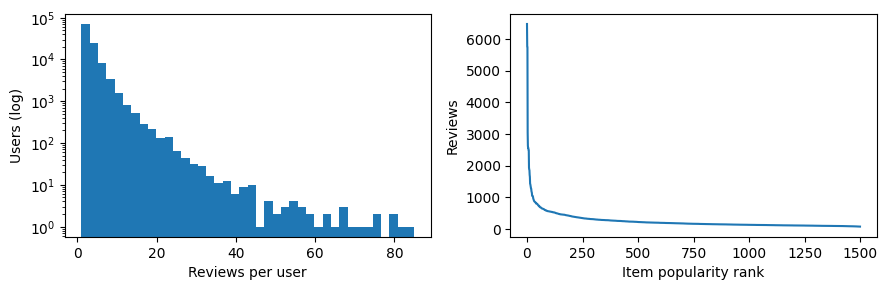

In [3]:
display(raw.isna().sum().rename("missing").to_frame())

print("Повторные user-item:", raw.duplicated(["user", "item"]).sum())
print(f"Разреженность: {1 - len(sample) / np.prod(shape):%}")
print("Товаров в исходных метаданных:", len(metadata))
print("Ветвей каталога:", item_metadata.category.nunique(),
      "| unknown:", item_metadata.category.eq("unknown").sum())

display(item_metadata.category.value_counts().head(10).rename("items").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(sample.groupby("user").size(), bins=40, log=True)
axes[0].set(xlabel="Reviews per user", ylabel="Users (log)")
axes[1].plot(sample.groupby("item").size().sort_values(ascending=False).to_numpy())
axes[1].set(xlabel="Item popularity rank", ylabel="Reviews")
plt.tight_layout()
plt.show()

## 3. Протокол оценки
Все очищенные отзывы делим по времени примерно в пропорции 70/15/15.

- Train: ранние 70% отзывов для обучения.
- Validation: следующие 15% для выбора настроек.
- Test: последние 15% для итоговой проверки.

Отзывы одной даты оставляем в одной части. Затем оставляем в каждой части отзывы только о 1500 товарах, выбранных по популярности в train.

Оцениваем всех пользователей с историей в train и хотя бы одним товаром с оценкой 4 или 5 в проверяемой части. Это даёт известные положительные ответы для проверки рекомендаций.

Каждому пользователю предлагаем 10 товаров из каталога на 1500 товаров. Уже оценённые товары исключаем. Разбиение, пользователи и кандидаты одинаковы для всех моделей.

In [4]:
R_train = rating_matrix(train, shape)
R_final = rating_matrix(pd.concat([train, validation]), shape)
val_users, val_truth = evaluation_set(validation, train.u.unique())
test_users, test_truth = evaluation_set(test, train.u.unique())
display(pd.DataFrame([
    {"period": name, "cold_user_events_excluded": (~frame.u.isin(train.u)).sum(),
     "evaluated_users": len(users)}
    for name, frame, users, truth in [("validation", validation, val_users, val_truth),
                                     ("test", test, test_users, test_truth)]
]).set_index("period"))

,cold_user_events_excluded,evaluated_users
period,,
validation,23138,12566
test,25145,10180


## 4. Модели и подбор гиперпараметров
$R_{ui}$ содержит оценку. $O_{ui}=1$ при наличии отзыва. $P_{ui}=\mathbf{1}[O_{ui}=1\land R_{ui}\geq4]$ показывает, понравился ли товар пользователю.

### ItemKNN
Считаем косинусное сходство товаров:
$$S_{ij}=\frac{\sum_u P_{ui}P_{uj}}{\sqrt{\sum_u P_{ui}^2}\sqrt{\sum_u P_{uj}^2}},\quad i\ne j,\quad S_{ii}=0.$$
В каждом столбце оставляем `neighbors` наибольших сходств. Оценки кандидатов: $PS$.

### ALS
Подбираем векторы пользователей $x_u$ и товаров $y_i$:
$$L=\sum_{u,i}c_{ui}(P_{ui}-x_u^Ty_i)^2+\lambda\left(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\right),\quad c_{ui}=1+20O_{ui}.$$
Фиксируем одну сторону и решаем линейные системы для другой. 16 обучаемых параметров для каждого пользователя и товара, 6 проходов. Оценка кандидата: $x_u^Ty_i$.

### EASE
$$\min_B\|P-PB\|_F^2+\lambda\|B\|_F^2,\quad B_{ii}=0.$$
Находим $A=(P^TP+\lambda I)^{-1}$ через линейную систему. Для $i\ne j$: $B_{ij}=-A_{ij}/A_{jj}$. Оценки кандидатов: $PB$.

### FM
Признаки $z$: user ID, item ID и `category`. Категория позволяет учитывать интересы к группе товаров. Считаем что категория известна до рекомендации и не меняется со временем.
$$f(z)=b+\sum_a w_a z_a+\sum_{a<b}\langle v_a,v_b\rangle z_a z_b.$$
Обучаем на наблюдаемых оценках:
$$L=\frac1{|\Omega|}\sum_{(u,i)\in\Omega}(f(z_{ui})-R_{ui})^2+\frac{\lambda}{2}\|\theta\|_2^2.$$
Adam: 5 эпох, batch=4096, lr=0.01, L2=1e-5. Для ранжирования используем $f(z)$.

### CustomALS
Меняем целевой сигнал ALS:
$$p_{ui}=\begin{cases}(R_{ui}-1)/4,&O_{ui}=1,\\0,&O_{ui}=0.\end{cases}$$
Так сохраняем всю шкалу оценок, чтобы товары с оценкой 4 и 5 отличались друг от друга. Вес ошибки $c_{ui}=1+20O_{ui}$, обучение и подбор такие же, как у ALS. При оценке релевантны только товары с оценкой ≥4.

### Подбор гиперпараметров
Проверяем по две комбинации из `grids`. Выбираем максимум NDCG@10 на validation.

In [5]:
grids = {
    "ItemKNN": [{"neighbors": 20}, {"neighbors": 80}],
    "ALS": [{"reg": 1.0}, {"reg": 10.0}],
    "EASE": [{"reg": 100.0}, {"reg": 500.0}],
    "FM": [{"factors": 8}, {"factors": 16}],
    "CustomALS": [{"reg": 1.0}, {"reg": 10.0}],
}
constructors = {"ItemKNN": ItemKNN, "ALS": ALS, "EASE": EASE, "FM": FM,
                "CustomALS": CustomALS}

def fit_model(name, params, ratings):
    model = constructors[name](**params)
    if name == "FM":
        return model.fit(ratings, category_codes)
    if name in ["ItemKNN", "EASE"]:
        ratings = positive_matrix(ratings)
    return model.fit(ratings)

trials = []
best_params = {}
for name, grid in grids.items():
    best = -1
    for params in grid:
        model = fit_model(name, params, R_train)
        metrics = evaluate(model, val_users, val_truth, R_train)
        trials.append({"model": name, "params": params, **metrics})
        if metrics[PRIMARY_METRIC] > best:
            best = metrics[PRIMARY_METRIC]
            best_params[name] = params
validation_results = pd.DataFrame(trials)
display(validation_results)

,model,params,Recall@10,NDCG@10
0,ItemKNN,{'neighbors': 20},0.071682,0.044337
1,ItemKNN,{'neighbors': 80},0.074053,0.044811
2,ALS,{'reg': 1.0},0.048759,0.029811
3,ALS,{'reg': 10.0},0.048824,0.029662
4,EASE,{'reg': 100.0},0.078229,0.048234
5,EASE,{'reg': 500.0},0.081179,0.048944
6,FM,{'factors': 8},0.010029,0.005085
7,FM,{'factors': 16},0.010590,0.005212
8,CustomALS,{'reg': 1.0},0.051988,0.031719
9,CustomALS,{'reg': 10.0},0.052328,0.031813


## 5. Сравнение моделей

K=10. Recall@10 показывает, какую долю товаров с оценками 4 или 5 удалось найти в десяти рекомендациях. Так оцениваем полноту рекомендаций.

NDCG@10 учитывает позиции найденных товаров. Для топ 10 важно поставить подходящие товары в начало списка. Поэтому настройки выбираем по NDCG@10.

Обе метрики усредняем по пользователям.

In [6]:
rows = []
for name, params in best_params.items():
    model = fit_model(name, params, R_final)
    rows.append({"model": name, "params": params,
                 **evaluate(model, test_users, test_truth, R_final)})
results = pd.DataFrame(rows).set_index("model").sort_values(PRIMARY_METRIC, ascending=False)
display(results)

,params,Recall@10,NDCG@10
model,,,
EASE,{'reg': 500.0},0.074057,0.044386
ItemKNN,{'neighbors': 80},0.067627,0.041602
CustomALS,{'reg': 10.0},0.049558,0.028114
ALS,{'reg': 1.0},0.047472,0.026554
FM,{'factors': 16},0.009779,0.004794


## 6. Выводы
Лучшие метрики на test у EASE с reg=500. NDCG@10 равен 0.0444. Recall@10 равен 0.0741.

При одинаковом reg=10 новый сигнал ALS повысил NDCG@10 на validation с 0.0297 до 0.0318. На test ALS получил 0.0266 с reg=1. CustomALS получил 0.0281 с reg=10. Разница на test включает влияние разных настроек регуляризации.

FM с категорией товара получил NDCG@10 = 0.0048. Влияние самой категории отдельно не проверяли.

Ограничения: 1500 популярных товаров, только пользователи с историей, один seed и две настройки. Категории считаем постоянными, хотя метаданные собраны позже.